In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.OPTIMIZER_NAME,
            config.LEARNING_RATE,
            # config.DROPOUT_P,
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


opti = [
    ("SGD", 0.001),
    # ("SGD", 0.01),
    # ("SGD", 0.1),
    # ("Adam", 0.0001),
    # ("Adam", 0.001),
    # ("Adam", 0.01)
]

batches = [
    64,
    # 100,
    # 256,
    # 512
]

neurons = [
    (64, 32),
    # (128, 64),
    # (256, 128),
    # (512, 256)
]

dropout = [
     # 0,
    # 0.2,
     0.5
]

# Adam-0.001/128-64/B512/D0.2 we have this
# Adam-0.001/128-64/B512/D0.5
def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=30,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 1




Optimizador: SGD
Dropout: 0.5

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.5 | Batch size -> 64
Training time: 134.75 seconds

Peak GPU memory: 18.00 MB

Test CEL: 0.65673
Test accuracy: 75.28%

----------------- SGD-0.001/64-32/B64/D0.5 -----------------


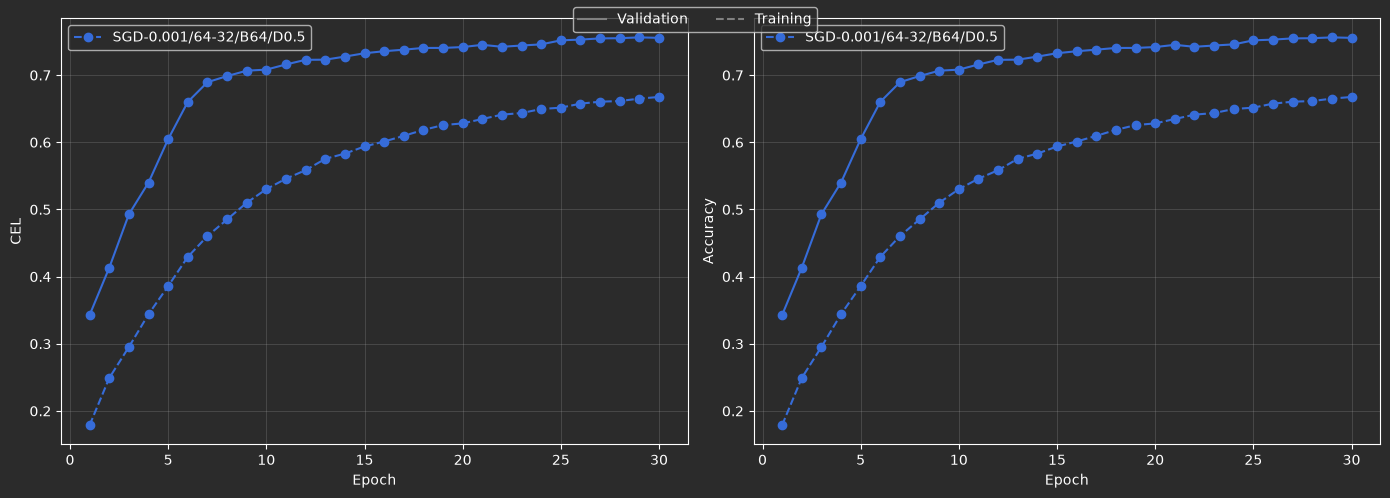

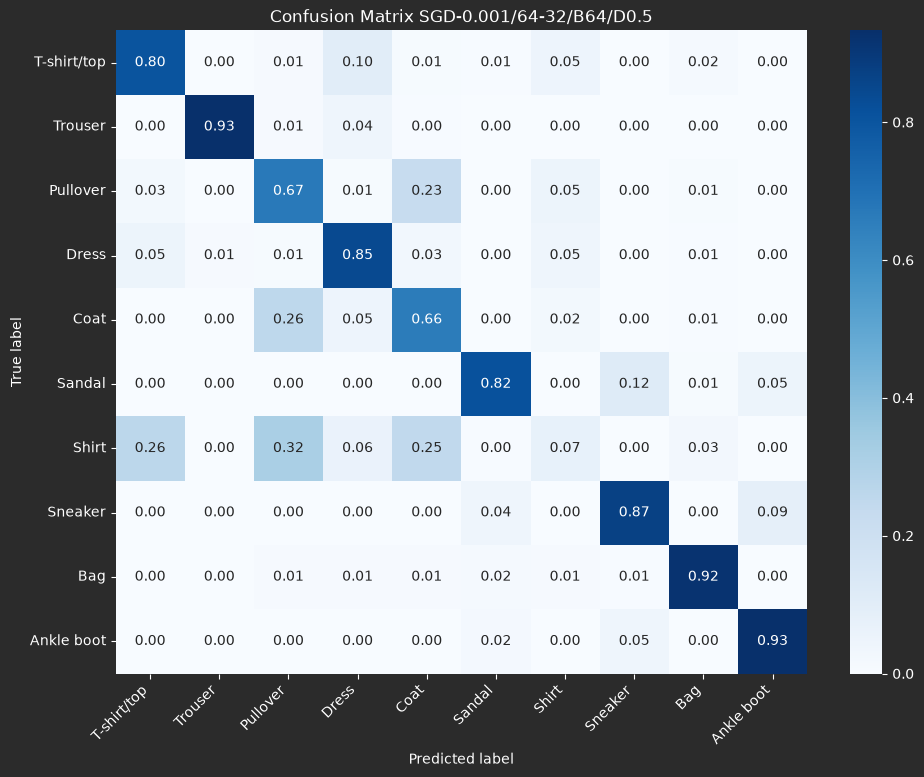

In [2]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: ('SGD', 0.001):-----------------------------------

----------------- SGD-0.001/64-32/B64/D0.5 -----------------


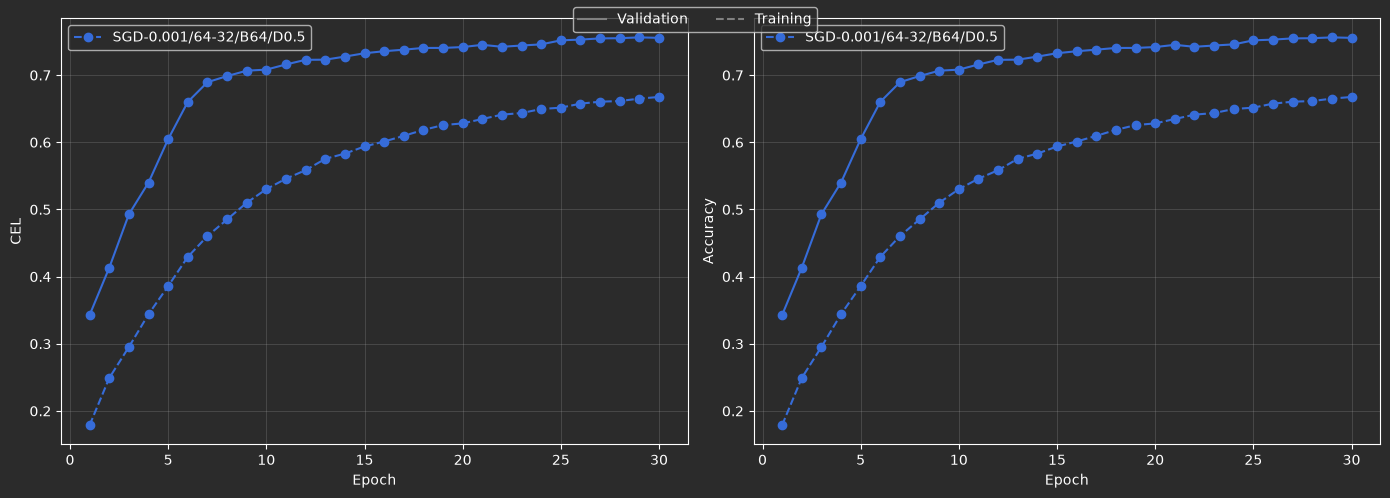

                         Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.001/64-32/B64/D0.5       0.89       0.65       0.67       0.76      0.75       Shirt               0.07  -0.09         1.62        134.75

--- Best experiments ---
Max Test Accu      -> SGD-0.001/64-32/B64/D0.5: 0.7528
Max Valid Accu     -> SGD-0.001/64-32/B64/D0.5: 0.7555
Best Worst-Class Recall -> SGD-0.001/64-32/B64/D0.5: Shirt (0.0740)
Min CM Deviation       -> SGD-0.001/64-32/B64/D0.5: 1.6211
Min Training Time       -> SGD-0.001/64-32/B64/D0.5: 134.8s
Min abs Generalization Gap  -> SGD-0.001/64-32/B64/D0.5: -0.08799999952316284
Max abs Generalization Gap  -> SGD-0.001/64-32/B64/D0.5: -0.08799999952316284

-----------------------------------ALL:-----------------------------------

                         Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.001/64

In [3]:
viewAftermath(aftermath)

import winsound
for _ in range(14):
    winsound.MessageBeep(winsound.MB_ICONEXCLAMATION)
    time.sleep(0.5)